# 5.2 Random Forest — Tala, Edrian

HeatCast NCR · predicts `HeatLevelTomorrow` (next-day maximum heat index level) for the 16 Metro Manila cities.

**Rules followed (workspace 4.1):** the shared chronological split and gap (`ncr_preprocessing.prepare_dataset`), the same 5
expanding-window folds, the shared transformer (`make_preprocessor`, fitted inside each training fold), `random_state = 42`
and the shared scoring (`ncr_model_eval`). **The test partition is never used in this notebook**. Only the model chosen in
Section 6 is evaluated on it, once.

Primary metric used for tuning: **macro F1 over the classes present in each validation block** (proposed in 4.1; the group
still has to confirm it). Danger recall, Danger precision and the Danger false-alarm rate are reported next to it.
The setup, selection rule and outputs mirror `05_1_logistic_regression.ipynb` so the two models can be compared directly in Section 6.

Run time: about 20 minutes on 4 cores (36 configurations × 5 folds).

In [1]:
import json, os, sys, time, warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().resolve()
if not (ROOT / "ncr_preprocessing.py").exists():   # opened from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import ncr_model_eval as E
import ncr_preprocessing as P

# Open group decision (workspace 4.3): "five_class" keeps the labels as built; "three_class" merges the rare classes.
# Feature sets the Streamlit app can collect from a user (4.3). "all_lags" (44 extra inputs) is tried for reference only.
APP_FEATURE_SETS = ["today", "hi_lags"]
TARGET_POLICY = os.environ.get("HEATCAST_TARGET_POLICY", "five_class")
RANDOM_STATE = P.RANDOM_STATE
OUT = ROOT / "results" / "random_forest" / TARGET_POLICY
OUT.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")
pd.set_option("display.float_format", "{:.3f}".format)
print("scikit-learn", sklearn.__version__, "| target policy:", TARGET_POLICY, "| outputs ->", OUT.relative_to(ROOT))

scikit-learn 1.9.1 | target policy: five_class | outputs -> results/random_forest/five_class


## 1. Data, split and folds (shared, from Section 4)

In [2]:
prep = P.prepare_dataset(ROOT / "data/ncr/output/ph_heat_index_next_day.csv", target_policy=TARGET_POLICY)
LABELS = prep.class_labels
print(prep.counts)
print("test starts", prep.test_start.date(), "- test rows are NOT used below")
P.class_count_table(prep)

{'rows_in': 64240, 'dropped_for_lag_history': 48, 'gap_rows': 64, 'train': 51280, 'test': 12848}
test starts 2023-10-18 - test rows are NOT used below


,train (all),fold 1 valid.,fold 2 valid.,fold 3 valid.,fold 4 valid.,fold 5 valid.,test
class,,,,,,,
Not Hazardous,158,32,22,13,0,40,0
Caution,7175,1352,1146,899,1116,1086,1510
Extreme Caution,39893,5818,6110,5985,6375,6288,10061
Danger,4054,702,626,1007,413,490,1277
Extreme Danger,0,0,0,0,0,0,0


## 2. Reference: persistence baseline on the same folds

Tomorrow's class = today's class. A model worth deploying has to beat it on macro F1 **and** catch at least as many Danger
days (workspace 1.6).

In [3]:
base = E.baseline_cv(prep.train, prep.cv_splits, LABELS, TARGET_POLICY)
BASE_F1, BASE_DANGER_RECALL = base["macro_f1"].mean(), base["danger_recall"].mean()
base.agg(["mean", "std"]).T.loc[["macro_f1", "accuracy", "balanced_accuracy", "danger_recall", "danger_precision",
                                 "danger_false_alarm_rate"]]

,mean,std
macro_f1,0.572,0.084
accuracy,0.835,0.026
balanced_accuracy,0.572,0.084
danger_recall,0.581,0.073
danger_precision,0.582,0.073
danger_false_alarm_rate,0.036,0.012


## 3. The model

`RandomForestClassifier` behind the shared transformer. A forest does not need scaling, and the monotone `log1p` and the
sin/cos day-of-year columns do not change what a tree can split on, so the **same transformer** as the other two models is
used on purpose: one preprocessing, one fair comparison. Class weights come from `E.PartialBalance`, which computes them from the
labels of each training fold only: `weight = (n / (k · n_class)) ** power` (`power = 1` is `class_weight="balanced"`, the 4.2
decision, `power = 0` is no weighting).

Hyperparameters tuned:

* `max_depth` (how deep each tree may grow), `min_samples_leaf` (smallest leaf; the main guard against over-fitting rows that
  are near-copies, since the 16 cities share only 2 ERA5 grid cells) and `max_features` (inputs tried at each split);
* `n_estimators` (number of trees; more trees only lower the variance, so it is checked last);
* the class-weight power, the feature set (`today` or `hi_lags`), the weather set and whether the city input is kept.

`oob_score` is **not** used: out-of-bag rows are random rows from the same period, so they are not a time-aware check. Only the 5
time-ordered folds are used.

In [4]:
def make_rf(feature_set="today", weather="full", static="city", n_estimators=300, max_depth=12, min_samples_leaf=5,
            max_features="sqrt", weight_power=0.5):
    clf = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                 max_features=max_features, random_state=RANDOM_STATE, n_jobs=1)
    return Pipeline([("prep", P.make_preprocessor(feature_set, static, weather)),
                     ("clf", E.PartialBalance(clf, power=weight_power))])


DEFAULTS = dict(feature_set="today", weather="full", static="city", n_estimators=300, max_depth=12,
                min_samples_leaf=5, max_features="sqrt", weight_power=0.5)
KEYS = list(DEFAULTS)
y_train = prep.y(prep.train)
X_cache = {}
def X_for(feature_set, weather="full", static="city"):
    key = (feature_set, weather, static)
    if key not in X_cache:
        X_cache[key] = prep.X(prep.train, feature_set, static, weather)
    return X_cache[key]


def run(config):
    cfg = {**DEFAULTS, **config}
    X = X_for(cfg["feature_set"], cfg["weather"], cfg["static"])
    res = E.cross_validate_model(make_rf(**cfg), X, y_train, prep.cv_splits, LABELS, n_jobs=4)
    row = {**cfg, "macro_f1_mean": res.mean(), "macro_f1_sd": res.sd(),
           "danger_recall_mean": res.mean("danger_recall"), "danger_precision_mean": res.mean("danger_precision"),
           "danger_false_alarm_mean": res.mean("danger_false_alarm_rate"), "balanced_acc_mean": res.mean("balanced_accuracy"),
           "accuracy_mean": res.mean("accuracy"), "n_inputs": X.shape[1], "fit_seconds": round(res.fit_seconds, 1)}
    return row, res

## 4. Tuning, stage 1: feature set × weather set

Same two choices as for Logistic Regression, with the forest settings at reasonable defaults and half-strength class
weights. Only `today` and `hi_lags` can be selected (`APP_FEATURE_SETS`): the app has to collect every input from a user.
`all_lags` is scored for reference, to show how much the extra history would add.

In [5]:
t0 = time.perf_counter()
stage1 = pd.DataFrame([run(dict(feature_set=fs, weather=wx))[0]
                       for fs in ["today", "hi_lags", "all_lags"] for wx in ["full", "lr_pruned"]])
stage1 = stage1.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
print(f"stage 1: {len(stage1)} configurations x 5 folds in {time.perf_counter() - t0:.0f} s")
stage1[["feature_set", "weather", "n_inputs", "macro_f1_mean", "macro_f1_sd", "danger_recall_mean",
        "danger_precision_mean", "accuracy_mean"]]

stage 1: 6 configurations x 5 folds in 166 s


,feature_set,weather,n_inputs,macro_f1_mean,macro_f1_sd,danger_recall_mean,danger_precision_mean,accuracy_mean
0,hi_lags,full,21,0.593,0.082,0.560,0.641,0.853
1,today,full,18,0.592,0.088,0.592,0.629,0.850
2,today,lr_pruned,9,0.583,0.084,0.605,0.597,0.843
3,hi_lags,lr_pruned,12,0.582,0.082,0.565,0.629,0.846
4,all_lags,full,62,0.578,0.078,0.536,0.683,0.858
5,all_lags,lr_pruned,35,0.571,0.086,0.522,0.651,0.853


## 5. Tuning, stage 2: tree size (`max_depth` × `min_samples_leaf` × `max_features`)

Run on the best app-feasible feature/weather combination of stage 1. Depth and leaf size control how closely a tree can
follow single days; `max_features` controls how different the trees are from each other.

In [6]:
best1 = stage1[stage1.feature_set.isin(APP_FEATURE_SETS)].iloc[0]
FS, WX = best1["feature_set"], best1["weather"]
print(f"best overall: {stage1.iloc[0].feature_set}/{stage1.iloc[0].weather} macro F1 {stage1.iloc[0].macro_f1_mean:.3f}; "
      f"best app-feasible: {FS}/{WX} macro F1 {best1.macro_f1_mean:.3f} (fold SD about {best1.macro_f1_sd:.3f})")
t0 = time.perf_counter()
stage2 = pd.DataFrame([run(dict(feature_set=FS, weather=WX, max_depth=d, min_samples_leaf=l, max_features=mf))[0]
                       for d in [4, 8, 12, None] for l in [5, 20, 50] for mf in ["sqrt", 0.5]])
print(f"stage 2: {len(stage2)} configurations in {time.perf_counter() - t0:.0f} s (feature_set={FS}, weather={WX})")
stage2["max_depth"] = stage2["max_depth"].astype(object).where(stage2["max_depth"].notna(), "None")
tab = stage2.assign(max_features=stage2.max_features.astype(str))
display(tab.pivot_table(index=["max_depth", "min_samples_leaf"], columns="max_features", values="macro_f1_mean", sort=False))
display(tab.pivot_table(index=["max_depth", "min_samples_leaf"], columns="max_features", values="danger_recall_mean", sort=False))

best overall: hi_lags/full macro F1 0.593; best app-feasible: hi_lags/full macro F1 0.593 (fold SD about 0.082)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


stage 2: 24 configurations in 891 s (feature_set=hi_lags, weather=full)


max_features                sqrt   0.5
max_depth min_samples_leaf            
4.000     5                0.590 0.581
          20               0.590 0.580
          50               0.589 0.581
8.000     5                0.600 0.582
          20               0.597 0.590
          50               0.595 0.585
12.000    5                0.593 0.576
          20               0.597 0.588
          50               0.596 0.587
 None     5                0.585 0.571
          20               0.597 0.588
          50               0.596 0.586

max_features                sqrt   0.5
max_depth min_samples_leaf            
4.000     5                0.595 0.652
          20               0.598 0.650
          50               0.600 0.649
8.000     5                0.616 0.602
          20               0.629 0.617
          50               0.647 0.645
12.000    5                0.560 0.541
          20               0.616 0.608
          50               0.651 0.641
 None     5                0.517 0.509
          20               0.613 0.603
          50               0.647 0.644

## 6. Tuning, stage 3: class-weight strength, then number of trees

With the best tree size from stage 2, the weight power runs from 0 (none) to 1 (balanced). As in Logistic Regression, the
trade-off is between catching Danger days (recall) and raising false Danger alarms (precision, false-alarm rate).

In [7]:
b2 = stage2.sort_values("macro_f1_mean", ascending=False).iloc[0]
TREE = dict(max_depth=(None if b2["max_depth"] == "None" else int(b2["max_depth"])),
            min_samples_leaf=int(b2["min_samples_leaf"]), max_features=b2["max_features"])
print("best tree size from stage 2:", TREE, f"macro F1 {b2.macro_f1_mean:.3f}")
t0 = time.perf_counter()
stage3 = pd.DataFrame([run(dict(feature_set=FS, weather=WX, **TREE, weight_power=pw))[0]
                       for pw in [0.0, 0.25, 0.5, 0.75, 1.0]])
print(f"stage 3: {len(stage3)} configurations in {time.perf_counter() - t0:.0f} s")
stage3[["weight_power", "macro_f1_mean", "macro_f1_sd", "danger_recall_mean", "danger_precision_mean",
        "danger_false_alarm_mean", "accuracy_mean"]]

best tree size from stage 2: {'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt'} macro F1 0.600


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


stage 3: 5 configurations in 98 s


,weight_power,macro_f1_mean,macro_f1_sd,danger_recall_mean,danger_precision_mean,danger_false_alarm_mean,accuracy_mean
0,0.000,0.568,0.079,0.408,0.739,0.012,0.855
1,0.250,0.586,0.079,0.511,0.689,0.020,0.854
2,0.500,0.600,0.083,0.616,0.607,0.034,0.851
3,0.750,0.582,0.082,0.705,0.509,0.058,0.825
4,1.000,0.572,0.064,0.783,0.425,0.093,0.785


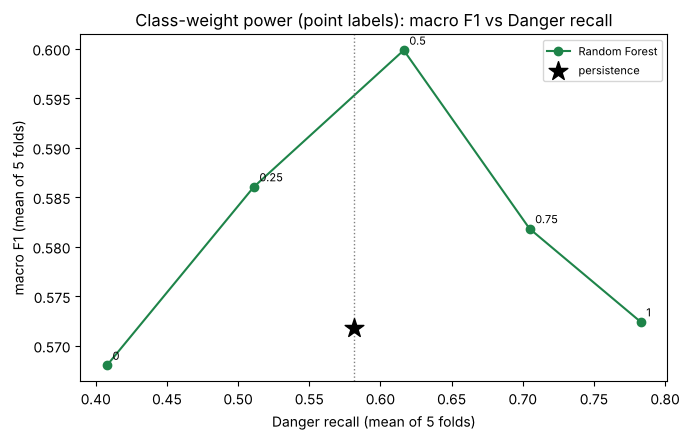

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(stage3["danger_recall_mean"], stage3["macro_f1_mean"], "o-", color="#1e8449", label="Random Forest")
for _, r in stage3.iterrows():
    ax.annotate(f"{r.weight_power:g}", (r.danger_recall_mean, r.macro_f1_mean), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.scatter([BASE_DANGER_RECALL], [BASE_F1], marker="*", s=200, color="black", label="persistence", zorder=5)
ax.axvline(BASE_DANGER_RECALL, color="grey", ls=":", lw=1)
ax.set_xlabel("Danger recall (mean of 5 folds)")
ax.set_ylabel("macro F1 (mean of 5 folds)")
ax.set_title("Class-weight power (point labels): macro F1 vs Danger recall")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "figure_M2a_weight_tradeoff.png", dpi=200)
plt.show()

In [9]:
# Number of trees: more trees only reduce variance, so this is checked last, with the best weight power.
eligible3 = stage3[stage3.danger_recall_mean >= BASE_DANGER_RECALL]
b3 = (eligible3 if len(eligible3) else stage3).sort_values("macro_f1_mean", ascending=False).iloc[0]
PW = float(b3["weight_power"])
t0 = time.perf_counter()
stage4 = pd.DataFrame([run(dict(feature_set=FS, weather=WX, **TREE, weight_power=PW, n_estimators=n))[0]
                       for n in [100, 300, 600]])
print(f"stage 4 (trees, weight_power={PW:g}): {len(stage4)} configurations in {time.perf_counter() - t0:.0f} s")
stage4[["n_estimators", "macro_f1_mean", "macro_f1_sd", "danger_recall_mean", "danger_precision_mean", "fit_seconds"]]

stage 4 (trees, weight_power=0.5): 3 configurations in 71 s


,n_estimators,macro_f1_mean,macro_f1_sd,danger_recall_mean,danger_precision_mean,fit_seconds
0,100,0.598,0.082,0.612,0.610,17.300
1,300,0.600,0.083,0.616,0.607,50.900
2,600,0.600,0.081,0.616,0.607,99.700


## 7. Selected Random Forest configuration

**Selection rule (same as Logistic Regression):** among the app-feasible configurations, the highest mean validation macro F1
among those whose mean Danger recall is at least the persistence baseline's (a heat-warning model must not miss more Danger
days than "tomorrow = today"). The city input is then dropped if that does not lower macro F1 by more than one fold-SD (fewer
inputs for the app). Fewer trees are preferred when macro F1 is within 0.002 (a smaller file, same skill).

In [10]:
grid = pd.concat([stage1.assign(stage=1), stage2.assign(stage=2), stage3.assign(stage=3), stage4.assign(stage=4)],
                 ignore_index=True)
grid["max_depth"] = grid["max_depth"].astype(object).where(grid["max_depth"].notna(), "None")
grid["max_features"] = grid["max_features"].astype(str)
grid = grid.drop_duplicates(subset=KEYS).sort_values("macro_f1_mean", ascending=False)
pool = grid[grid.feature_set.isin(APP_FEATURE_SETS)]
eligible = pool[pool.danger_recall_mean >= BASE_DANGER_RECALL]
if len(eligible) == 0:
    print("No configuration reaches persistence Danger recall; selecting by macro F1 alone.")
    eligible = pool
top = eligible.macro_f1_mean.max()
sel = eligible[eligible.macro_f1_mean >= top - 0.002].sort_values(["n_estimators", "macro_f1_mean"], ascending=[True, False]).iloc[0]

def to_cfg(row):
    c = {k: row[k] for k in KEYS}
    c["max_depth"] = None if c["max_depth"] == "None" else int(c["max_depth"])
    c["max_features"] = float(c["max_features"]) if c["max_features"] not in ("sqrt", "log2") else c["max_features"]
    for k in ("n_estimators", "min_samples_leaf"):
        c[k] = int(c[k])
    c["weight_power"] = float(c["weight_power"])
    return c

SELECTED = to_cfg(sel)
print("best with city input:", SELECTED, f"macro F1 {sel.macro_f1_mean:.3f} ± {sel.macro_f1_sd:.3f}")

no_city_row, _ = run({**SELECTED, "static": "none"})
grid = pd.concat([grid, pd.DataFrame([no_city_row]).assign(stage=5)], ignore_index=True)
if no_city_row["macro_f1_mean"] >= sel.macro_f1_mean - sel.macro_f1_sd and no_city_row["danger_recall_mean"] >= BASE_DANGER_RECALL:
    SELECTED["static"] = "none"
print(f"without city: macro F1 {no_city_row['macro_f1_mean']:.3f}, Danger recall {no_city_row['danger_recall_mean']:.3f}"
      f" -> city input '{SELECTED['static']}'")
grid = grid.sort_values("macro_f1_mean", ascending=False).reset_index(drop=True)
grid.to_csv(OUT / "cv_grid.csv", index=False)
print(f"{len(grid)} configurations tried; selected:", SELECTED)

_, res = run(SELECTED)
folds = res.folds
folds.to_csv(OUT / "selected_cv_folds.csv")
folds[["macro_f1", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "danger_recall",
       "danger_precision", "danger_false_alarm_rate", "qw_kappa", "roc_auc_ovr"]]

best with city input: {'feature_set': 'hi_lags', 'weather': 'full', 'static': 'city', 'n_estimators': 100, 'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'weight_power': 0.5} macro F1 0.598 ± 0.082


without city: macro F1 0.599, Danger recall 0.619 -> city input 'none'
36 configurations tried; selected: {'feature_set': 'hi_lags', 'weather': 'full', 'static': 'none', 'n_estimators': 100, 'max_depth': 8, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'weight_power': 0.5}


,macro_f1,accuracy,balanced_accuracy,macro_precision,macro_recall,danger_recall,danger_precision,danger_false_alarm_rate,qw_kappa,roc_auc_ovr
fold,,,,,,,,,,
1,0.623,0.830,0.582,0.803,0.582,0.583,0.613,0.036,0.657,0.902
2,0.544,0.843,0.539,0.555,0.539,0.708,0.651,0.033,0.634,0.932
3,0.537,0.822,0.535,0.538,0.535,0.632,0.674,0.045,0.624,0.867
4,0.736,0.877,0.743,0.729,0.743,0.571,0.515,0.030,0.674,0.927
5,0.556,0.872,0.560,0.554,0.560,0.604,0.539,0.034,0.686,0.938


### Validation summary vs persistence (mean ± SD over the 5 folds)

In [11]:
metrics = ["macro_f1", "accuracy", "balanced_accuracy", "macro_precision", "macro_recall", "danger_precision",
           "danger_recall", "danger_f1", "danger_false_alarm_rate", "qw_kappa", "roc_auc_ovr"]
def pm(df, m):
    return f"{df[m].mean():.3f} ± {df[m].std(ddof=1):.3f}" if m in df else "n/a"
compare = pd.DataFrame({"Random Forest": [pm(folds, m) for m in metrics],
                        "Persistence baseline": [pm(base, m) for m in metrics]}, index=metrics)
compare

,Random Forest,Persistence baseline
macro_f1,0.599 ± 0.084,0.572 ± 0.084
accuracy,0.849 ± 0.025,0.835 ± 0.026
balanced_accuracy,0.592 ± 0.087,0.572 ± 0.084
macro_precision,0.636 ± 0.122,0.572 ± 0.083
macro_recall,0.592 ± 0.087,0.572 ± 0.084
danger_precision,0.599 ± 0.069,0.582 ± 0.073
danger_recall,0.619 ± 0.054,0.581 ± 0.073
danger_f1,0.608 ± 0.057,0.582 ± 0.073
danger_false_alarm_rate,0.035 ± 0.006,0.036 ± 0.012
qw_kappa,0.655 ± 0.026,0.633 ± 0.034


### Figure M2. Random Forest confusion matrix (out-of-fold validation predictions, all 5 folds)

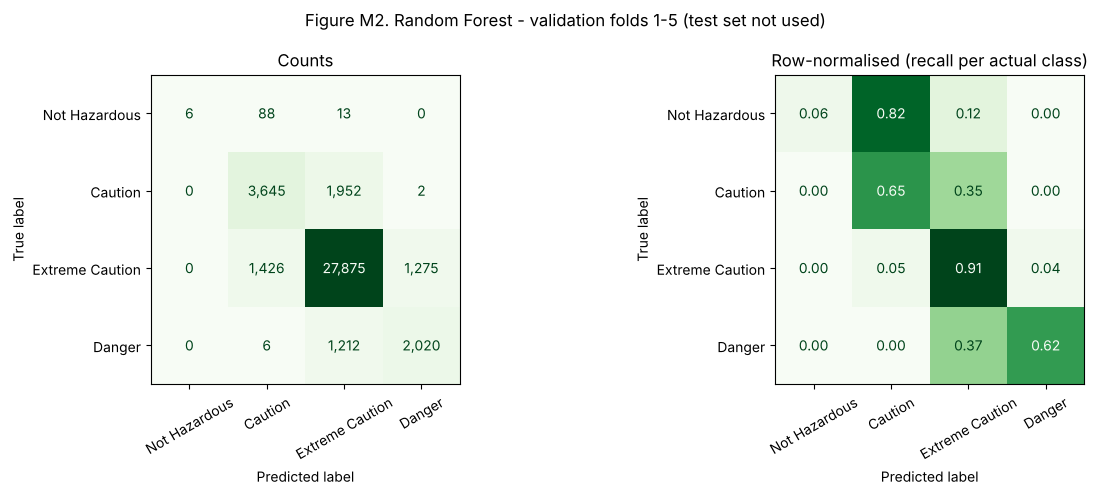

,precision,recall,f1,support
class,,,,
Not Hazardous,1.000,0.056,0.106,107
Caution,0.706,0.651,0.677,5599
Extreme Caution,0.898,0.912,0.905,30576
Danger,0.613,0.624,0.618,3238


In [12]:
cm = E.confusion_frame(res.oof_true, res.oof_pred, LABELS)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm.to_numpy(), display_labels=cm.index).plot(ax=axes[0], cmap="Greens", values_format=",d", colorbar=False)
axes[0].set_title("Counts")
norm = cm.div(cm.sum(axis=1), axis=0)
ConfusionMatrixDisplay(norm.to_numpy(), display_labels=cm.index).plot(ax=axes[1], cmap="Greens", values_format=".2f", colorbar=False)
axes[1].set_title("Row-normalised (recall per actual class)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("Figure M2. Random Forest - validation folds 1-5 (test set not used)")
fig.tight_layout()
fig.savefig(OUT / "figure_M2_confusion_matrix.png", dpi=200)
plt.show()
E.per_class_table(res.oof_true, res.oof_pred, LABELS)

## 8. Interpretation: which inputs the forest uses

The selected configuration is refitted on the **training partition only** (no test rows).

* *Impurity importance* is how much each input reduces node impurity inside the trees. It is biased toward inputs with many
  distinct values, so it is shown only as a first look.
* *Permutation importance* is measured on the **validation block of the last fold** with a model fitted on that fold's training days
  only: the drop in macro F1 when one input is shuffled. It is the more reliable of the two. Correlated inputs share credit, so
  a low value does not mean an input is useless on its own.

In [13]:
final = make_rf(**SELECTED)
X_sel = X_for(SELECTED["feature_set"], SELECTED["weather"], SELECTED["static"])
final.fit(X_sel, y_train)
names = final.named_steps["prep"].get_feature_names_out()
rf = final.named_steps["clf"].estimator_
print("class weights used:", {LABELS[k]: round(v, 2) for k, v in final.named_steps["clf"].class_weight_.items()})
imp = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False)

# permutation importance on the last fold's validation block, model fitted on that fold's training days only
tr, va = prep.cv_splits[-1]
m5 = make_rf(**SELECTED).fit(X_sel.iloc[tr], y_train[tr])
Xv, yv = X_sel.iloc[va], y_train[va]
present = np.unique(yv)
perm = permutation_importance(m5, Xv, yv, scoring=lambda est, X, y: f1_score(y, est.predict(X), labels=present, average="macro", zero_division=0),
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=4)
perm_imp = pd.Series(perm.importances_mean, index=Xv.columns).sort_values(ascending=False)
# permutation importance works on the raw input columns (the transformer is inside the pipeline), so it is saved separately
imp.rename("impurity_importance").to_csv(OUT / "impurity_importance.csv")
perm_imp.rename("permutation_macro_f1_drop").to_csv(OUT / "permutation_importance.csv")
display(imp.head(12).to_frame("impurity importance (fitted model)"))
perm_imp.head(12).to_frame("macro F1 drop when shuffled (last fold)")

class weights used: {'Not Hazardous': 9.01, 'Caution': 1.34, 'Extreme Caution': 0.57, 'Danger': 1.78}


,impurity importance (fitted model)
HeatIndex_Max_Today,0.221
Temp_Mean,0.119
HeatIndex_Max_Today_lag1,0.089
DewPoint_Mean,0.082
Temp_Max,0.069
HeatIndex_Max_Today_lag2,0.058
Temp_Min,0.057
HeatIndex_Max_Today_lag3,0.051
DayOfYear_cos,0.045
DayOfYear_sin,0.030


,macro F1 drop when shuffled (last fold)
HeatIndex_Max_Today,0.098
Temp_Mean,0.031
DewPoint_Mean,0.025
DayOfYear,0.022
Temp_Max,0.005
HeatIndex_Max_Today_lag1,0.004
SolarRadiation_Total,0.004
Temp_Min,0.003
Rainfall_Total,0.001
WindGust_Max,0.001


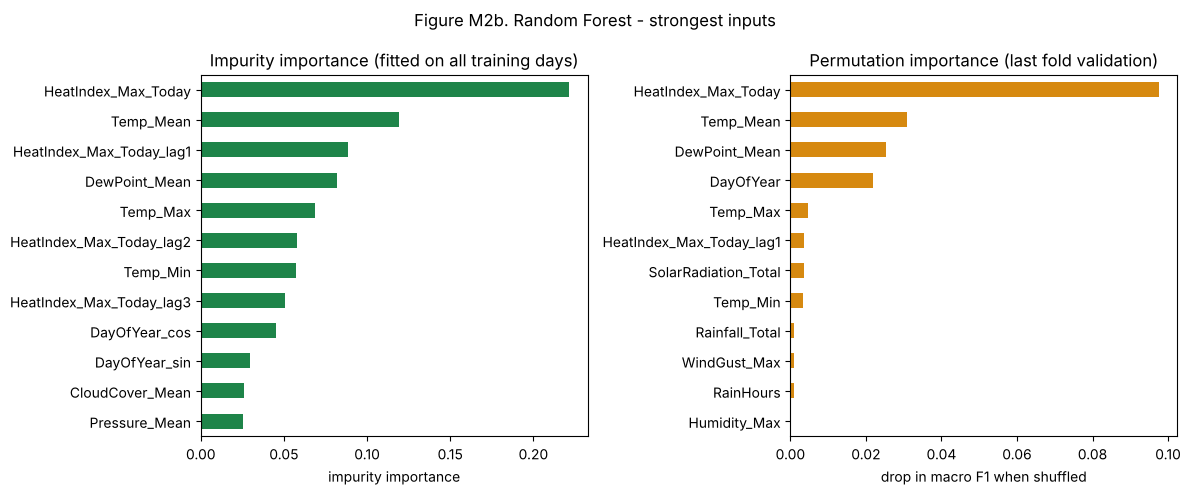

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
imp.head(12)[::-1].plot.barh(ax=axes[0], color="#1e8449")
axes[0].set_xlabel("impurity importance"); axes[0].set_title("Impurity importance (fitted on all training days)")
perm_imp.head(12)[::-1].plot.barh(ax=axes[1], color="#d68910")
axes[1].set_xlabel("drop in macro F1 when shuffled"); axes[1].set_title("Permutation importance (last fold validation)")
fig.suptitle("Figure M2b. Random Forest - strongest inputs")
fig.tight_layout()
fig.savefig(OUT / "figure_M2b_feature_importance.png", dpi=200)
plt.show()

## 9. Save the candidate model and the summary

The fitted pipeline (transformer + classifier) is saved as a **candidate**. Section 6 picks the best of the three models;
only that one goes to `models/` and is tested once on the untouched test set.

In [15]:
cand_dir = ROOT / "models" / "candidates"
cand_dir.mkdir(parents=True, exist_ok=True)
SELECTED = {k: (v.item() if hasattr(v, "item") else v) for k, v in SELECTED.items()}
cand_path = cand_dir / f"random_forest_{TARGET_POLICY}.joblib"
joblib.dump({"pipeline": final, "config": SELECTED, "target_policy": TARGET_POLICY, "class_labels": LABELS,
             "input_columns": list(X_sel.columns), "sklearn_version": sklearn.__version__}, cand_path, compress=3)
print(f"candidate size: {cand_path.stat().st_size / 1e6:.1f} MB")

summary = {"model": "Random Forest", "target_policy": TARGET_POLICY, "selected_config": SELECTED,
           "selection_rule": "max mean CV macro F1 subject to mean CV Danger recall >= persistence (fewest trees within 0.002)",
           "input_columns": list(X_sel.columns), "n_model_inputs_after_encoding": int(len(names)),
           "cv": {m: {"mean": float(folds[m].mean()), "sd": float(folds[m].std(ddof=1))} for m in metrics},
           "persistence_cv": {m: {"mean": float(base[m].mean()), "sd": float(base[m].std(ddof=1))}
                              for m in metrics if m in base},
           "top_impurity_importance": {k: float(v) for k, v in imp.head(8).items()},
           "top_permutation_importance": {k: float(v) for k, v in perm_imp.head(8).items()},
           "configurations_tried": int(len(grid)), "test_set_used": False}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  ")

candidate size: 1.3 MB
saved:
  cv_grid.csv
  figure_M2_confusion_matrix.png
  figure_M2a_weight_tradeoff.png
  figure_M2b_feature_importance.png
  impurity_importance.csv
  permutation_importance.csv
  selected_cv_folds.csv
  summary.json


## 10. Values for the workspace doc (Section 5.2)

In [16]:
cfg = SELECTED
print(f"""Hyperparameters tested ({len(grid)} configurations, same 5 folds)
  max_depth: 4, 8, 12, None -> selected {cfg['max_depth']}
  min_samples_leaf: 5, 20, 50 -> selected {cfg['min_samples_leaf']}
  max_features: sqrt, 0.5 -> selected {cfg['max_features']}
  n_estimators: 100, 300, 600 -> selected {cfg['n_estimators']}
  Other: class-weight power 0, 0.25, 0.5, 0.75, 1 (1 = balanced) -> selected {cfg['weight_power']:g};
         feature set '{cfg['feature_set']}', weather set '{cfg['weather']}', city input '{cfg['static']}';
         random_state=42

Results (validation, mean ± SD over 5 folds; test set not used)        persistence
  CV primary metric (macro F1)  {pm(folds, 'macro_f1'):16s}  {pm(base, 'macro_f1')}
  Accuracy                      {pm(folds, 'accuracy'):16s}  {pm(base, 'accuracy')}
  Precision (macro)             {pm(folds, 'macro_precision'):16s}  {pm(base, 'macro_precision')}
  Recall (macro)                {pm(folds, 'macro_recall'):16s}  {pm(base, 'macro_recall')}
  F1 score (macro)              {pm(folds, 'macro_f1'):16s}  {pm(base, 'macro_f1')}
  ROC-AUC (one-vs-rest, macro)  {pm(folds, 'roc_auc_ovr'):16s}  n/a
  Danger recall                 {pm(folds, 'danger_recall'):16s}  {pm(base, 'danger_recall')}
  Danger precision              {pm(folds, 'danger_precision'):16s}  {pm(base, 'danger_precision')}
  Danger false-alarm rate       {pm(folds, 'danger_false_alarm_rate'):16s}  {pm(base, 'danger_false_alarm_rate')}""")

Hyperparameters tested (36 configurations, same 5 folds)
  max_depth: 4, 8, 12, None -> selected 8
  min_samples_leaf: 5, 20, 50 -> selected 5
  max_features: sqrt, 0.5 -> selected sqrt
  n_estimators: 100, 300, 600 -> selected 100
  Other: class-weight power 0, 0.25, 0.5, 0.75, 1 (1 = balanced) -> selected 0.5;
         feature set 'hi_lags', weather set 'full', city input 'none';
         random_state=42

Results (validation, mean ± SD over 5 folds; test set not used)        persistence
  CV primary metric (macro F1)  0.599 ± 0.084     0.572 ± 0.084
  Accuracy                      0.849 ± 0.025     0.835 ± 0.026
  Precision (macro)             0.636 ± 0.122     0.572 ± 0.083
  Recall (macro)                0.592 ± 0.087     0.572 ± 0.084
  F1 score (macro)              0.599 ± 0.084     0.572 ± 0.084
  ROC-AUC (one-vs-rest, macro)  0.913 ± 0.029     n/a
  Danger recall                 0.619 ± 0.054     0.581 ± 0.073
  Danger precision              0.599 ± 0.069     0.582 ± 0.073
  Da